# Exploratory Data Analysis: Superstore Retail Sales

**Objective:** Analyze customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity to find commercial insights.

**Data:** Superstore orders, Jan 2015 to Dec 2018.
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn)


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [27]:
df=pd.read_csv("superstore_sales.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [29]:
bad = df[df["Sales"].isnull()]
print(bad.shape)
bad.head(10)

(806, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
df.duplicated().sum()


np.int64(504)

In [31]:
df[pd.to_numeric(df["Row ID"], errors="coerce").isnull()].head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
df[df["Postal Code"].isnull()][["City", "State", "Postal Code"]].drop_duplicates()

,City,State,Postal Code
2234,Burlington,Vermont,NaN
9994,NaN,NaN,NaN


## 1. Data Loading and Cleaning

**Findings from profiling:**
- The CSV had 10,800 rows, but only 9,994 were sales records. The other 806 rows were the *People* and *Returns* tables from other workbook sheets, pasted below the sales data.
- I separated those rows into their own tables (`people`, `returns`) and kept only the sales data.
- One genuine missing value: the Postal Code for Burlington, VT, which I filled with 05401.
- After cleaning: **9,994 rows, 21 columns, 0 missing values, 0 duplicates.**

In [33]:
# Rows with a Sales value are the real sales data
is_sales = df["Sales"].notnull()
extra = df[~is_sales]

# Set aside the Returns table (useful for later)
returns = extra[extra["Row ID"] == "Yes"][["Order ID"]].rename(columns={"Order ID": "Returned_Order_ID"}).drop_duplicates()

# Set aside the People table
people = extra[extra["Order ID"].isin(["West", "East", "Central", "South"])][["Row ID", "Order ID"]]
people.columns = ["Person", "Region"]

# Keep only the real sales data
df = df[is_sales].copy()
df["Row ID"] = df["Row ID"].astype(int)

# Fill the missing Burlington, VT postal code
df.loc[df["City"].eq("Burlington") & df["State"].eq("Vermont"), "Postal Code"] = 5401

print(df.shape)
print(df.isnull().sum().sum(), "missing values left")
print(df.duplicated().sum(), "duplicate rows")

(9994, 21)
0 missing values left
0 duplicate rows


## 2. Date Parsing and Feature Engineering

Order and ship dates were stored as text (month/day/year). I converted them to datetime and created `Year`, `Month` and `Year_Month` columns. `Quantity` and `Row_ID` were converted to integers.

Orders span **2015-01-03 to 2018-12-30**, four full years.

In [34]:
# Standardize column names (spaces and hyphens become underscores)
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")

# Parse dates (month/day/year format)
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%m/%d/%Y")
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"], format="%m/%d/%Y")

# Time features
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Year_Month"] = df["Order_Date"].dt.to_period("M")

print(df.columns.tolist())
df[["Order_Date", "Year", "Month", "Year_Month"]].head()

['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Year_Month']


,Order_Date,Year,Month,Year_Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10


In [35]:
print(df["Order_Date"].min(), "to", df["Order_Date"].max())
df.dtypes

2015-01-03 00:00:00 to 2018-12-30 00:00:00


Row_ID                    int64
Order_ID                    str
Order_Date       datetime64[us]
Ship_Date        datetime64[us]
Ship_Mode                   str
Customer_ID                 str
Customer_Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal_Code             float64
Region                      str
Product_ID                  str
Category                    str
Sub_Category                str
Product_Name                str
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
Year                      int32
Month                     int32
Year_Month            period[M]
dtype: object

In [36]:
df["Quantity"] = df["Quantity"].astype(int)

## 3. Revenue and Profit by Category, Region and Segment

Total sales are **$2.30M** and total profit is **$286K** (12.5% margin).

**Observations:**
- **Category:** Technology leads in sales ($836K, 17.4% margin). Furniture has similar sales ($742K) but only a **2.5% margin**.
- **Sub-category:** Tables (-$17.7K) and Bookcases (-$3.5K) lose money overall.
- **Region:** West (14.9%) and East (13.5%) are strongest. **Central (7.9%)** is the weakest.
- **Segment:** Consumer is about 51% of sales but has the lowest margin (11.5%). Home Office has the highest (14.0%).

In [37]:
# Sales and Profit by Category
cat = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order_ID", "nunique")
).round(2)
cat["Margin_%"] = (cat["Profit"] / cat["Sales"] * 100).round(1)
cat.sort_values("Sales", ascending=False)

,Sales,Profit,Orders,Margin_%
Category,,,,
Technology,836154.03,145454.95,1544,17.4
Furniture,741999.80,18451.27,1764,2.5
Office Supplies,719047.03,122490.80,3742,17.0


In [38]:
# Sales and Profit by Region
reg = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).round(2)
reg["Margin_%"] = (reg["Profit"] / reg["Sales"] * 100).round(1)
reg.sort_values("Sales", ascending=False)

,Sales,Profit,Margin_%
Region,,,
West,725457.82,108418.45,14.9
East,678781.24,91522.78,13.5
Central,501239.89,39706.36,7.9
South,391721.90,46749.43,11.9


In [39]:
# Sales and Profit by Segment
seg = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).round(2)
seg["Margin_%"] = (seg["Profit"] / seg["Sales"] * 100).round(1)
seg.sort_values("Sales", ascending=False)

,Sales,Profit,Margin_%
Segment,,,
Consumer,1161401.34,134119.21,11.5
Corporate,706146.37,91979.13,13.0
Home Office,429653.15,60298.68,14.0


In [40]:
# Sub-category profit (often where the interesting findings are)
df.groupby("Sub_Category")["Profit"].sum().sort_values().round(2)

Sub_Category
Tables        -17725.48
Bookcases      -3472.56
Supplies       -1189.10
Fasteners        949.52
Machines        3384.76
Labels          5546.25
Art             6527.79
Envelopes       6964.18
Furnishings    13059.14
Appliances     18138.01
Storage        21278.83
Chairs         26590.17
Binders        30221.76
Paper          34053.57
Accessories    41936.64
Phones         44515.73
Copiers        55617.82
Name: Profit, dtype: float64

## 4. Monthly Seasonality

**Observations:**
- Sales grow year over year, with a rising trend visible in the monthly line chart.
- There is a clear **Q4 peak**: November, December and September are the strongest months on average.
- January and February are the weakest months.

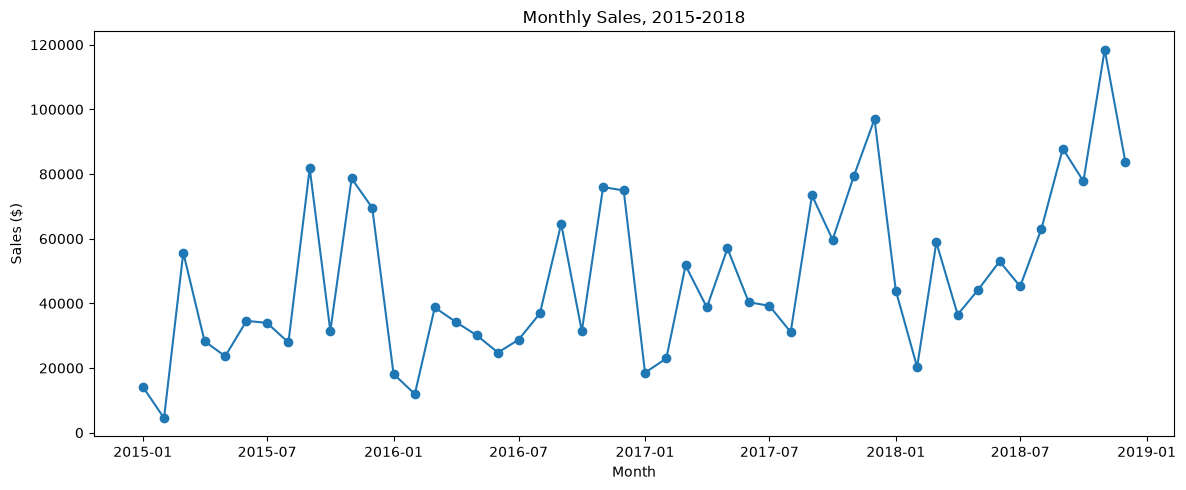

In [41]:
monthly = df.groupby("Year_Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales, 2015-2018")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

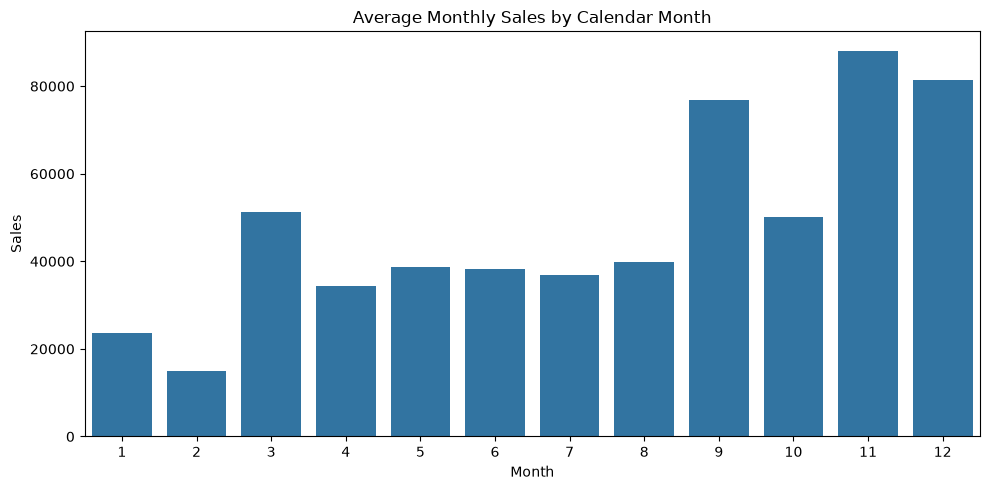

In [42]:
# Average sales by calendar month (shows seasonality clearly)
by_month = df.groupby(["Year", "Month"])["Sales"].sum().reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=by_month, x="Month", y="Sales", estimator="mean", errorbar=None)
plt.title("Average Monthly Sales by Calendar Month")
plt.tight_layout()
plt.show()

## 5. Discount Sensitivity

**Observations:**
- Average profit per order line is positive up to a 20% discount ($24.70 at 20%) but **turns negative from 30% onward**, reaching -$310.70 at 50%.
- The 1,393 order lines discounted 30% or more lost a combined **$135K**, equal to about 47% of total net profit.
- Zero-discount lines (4,798 of them) earn an average of $66.90 profit.

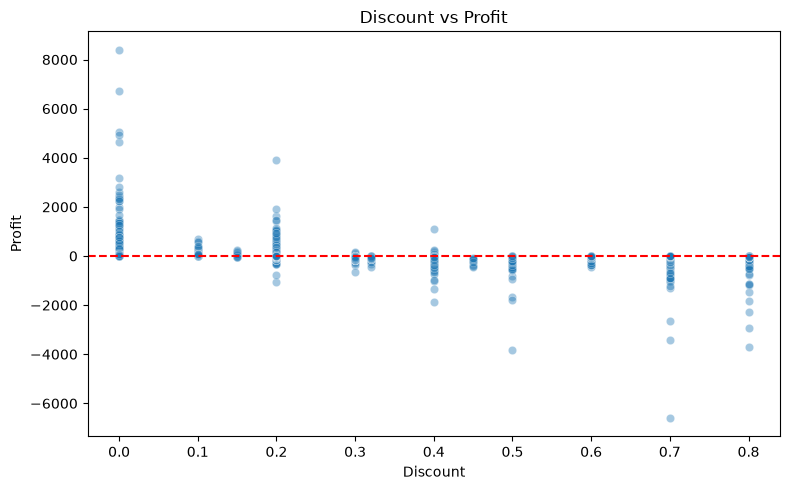

In [43]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.title("Discount vs Profit")
plt.tight_layout()
plt.show()

In [44]:
# Average profit by discount level
df.groupby("Discount")["Profit"].agg(["mean", "sum", "count"]).round(2)

,mean,sum,count
Discount,,,
0.00,66.90,320987.60,4798
0.10,96.06,9029.18,94
0.15,27.29,1418.99,52
0.20,24.70,90337.31,3657
0.30,-45.68,-10369.28,227
0.32,-88.56,-2391.14,27
0.40,-111.93,-23057.05,206
0.45,-226.65,-2493.11,11
0.50,-310.70,-20506.43,66


## 6. Customer Purchase Volume

**Observations:**
- The 793 customers placed a median of **6 orders** each over four years (range 1 to 17), and most placed between 5 and 8.
- The top 10 customers account for only **6.7%** of total sales, so revenue does not depend on a few large accounts.
- **Highest sales does not mean highest profit.** The top customer, Sean Miller ($25,043), generated a net **loss of $1,981**.

In [45]:
# Customer purchase volume
cust = df.groupby(["Customer_ID", "Customer_Name"]).agg(
    Orders=("Order_ID", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).sort_values("Sales", ascending=False).round(2)
cust.head(10)

,,Orders,Sales,Profit
Customer_ID,Customer_Name,,,
SM-20320,Sean Miller,5,25043.05,-1980.74
TC-20980,Tamara Chand,5,19052.22,8981.32
RB-19360,Raymond Buch,6,15117.34,6976.10
TA-21385,Tom Ashbrook,4,14595.62,4703.79
AB-10105,Adrian Barton,10,14473.57,5444.81
KL-16645,Ken Lonsdale,12,14175.23,806.86
SC-20095,Sanjit Chand,9,14142.33,5757.41
HL-15040,Hunter Lopez,6,12873.30,5622.43
SE-20110,Sanjit Engle,11,12209.44,2650.68


In [46]:
# Share of total sales from the top 10 customers
top10_share = cust["Sales"].head(10).sum() / cust["Sales"].sum() * 100
print(f"Top 10 customers: {top10_share:.1f}% of sales")

Top 10 customers: 6.7% of sales


count    793.000000
mean       6.316520
std        2.550885
min        1.000000
25%        5.000000
50%        6.000000
75%        8.000000
max       17.000000
Name: Orders, dtype: float64


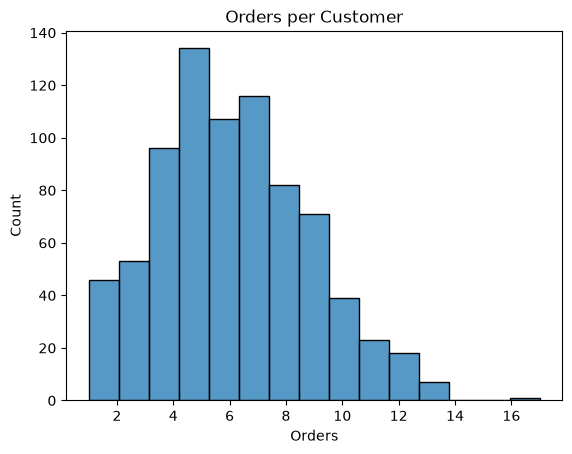

In [47]:
print(cust["Orders"].describe())
sns.histplot(cust["Orders"], bins=15)
plt.title("Orders per Customer")
plt.show()

In [48]:
# Year-over-year growth
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).round(2)
yearly["Growth_%"] = (yearly["Sales"].pct_change() * 100).round(1)
yearly

,Sales,Profit,Growth_%
Year,,,
2015,484247.50,49543.97,NaN
2016,470532.51,61618.60,-2.8
2017,609205.60,81795.17,29.5
2018,733215.26,93439.27,20.4


In [49]:
# Discount bands, which are easier to present than 12 separate values
df["Discount_Band"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1.0],
                             labels=["None", "1-20%", "21-40%", ">40%"])
df.groupby("Discount_Band", observed=True).agg(
    Lines=("Profit", "count"), Sales=("Sales", "sum"),
    Profit=("Profit", "sum"), Avg_Profit=("Profit", "mean")).round(2)

,Lines,Sales,Profit,Avg_Profit
Discount_Band,,,,
None,4798,1087908.47,320987.60,66.90
1-20%,3803,846522.24,100785.47,26.50
21-40%,460,234137.90,-35817.47,-77.86
>40%,933,128632.25,-99558.59,-106.71


In [50]:
# Does discounting explain the Tables losses?
df[df["Sub_Category"] == "Tables"].groupby("Discount")["Profit"].agg(["sum", "count"]).round(2)

,sum,count
Discount,,
0.00,13276.30,72
0.20,-303.56,71
0.30,-3402.33,54
0.40,-16187.40,75
0.45,-2493.11,11
0.50,-8615.39,36


## Executive Takeaways

1. **Discounts above 20% destroy profit.**
   
   Average profit per line is +$26.50 at 1-20% discount but -$77.86 at 21-40% and -$106.71 above 40%. The 1,393 lines discounted 30% or more lost $135K, about 47% of net profit.

   *Action:* Cap discounts at 20% unless there is a clear volume case.

2. **Sales peak strongly in Q4.**
   
   November, December and September are the strongest months on average, while January and February are the weakest.

   *Action:* Build inventory and run marketing ahead of Q4, and use promotions to lift the slow early-year months.

3. **Furniture is high revenue but low profit.**
   
   A 2.5% margin against about 17% for Technology and Office Supplies; Tables lose $17.7K and Bookcases $3.5K.

   *Action:* Review Furniture pricing and discount rules, starting with Tables.

4. **The Central region underperforms.**
   
   A 7.9% margin against 14.9% for West and 13.5% for East.

   *Action:* Check whether heavy discounting or product mix is behind it.

5. **Growth is strong, but profit is not keeping pace.**
   
   Sales grew 29.5% in 2017 and 20.4% in 2018, but the margin slipped from 13.4% to 12.7% in 2018. Consumer, the largest segment, has the lowest margin (11.5%).
   
   *Action:* Protect margin while growing, by tightening discounts and shifting Consumer promotions to higher-margin categories.